In [ ]:
# Bank Marketing Campaign Analysis

## 1. Importing Libraries

This project analyzes customer data to understand
the effectiveness of bank marketing campaigns.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
## 2. Loading the Dataset

In [6]:
import os

print("Current Location:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Current Location:
C:\Users\siddh\Documents

Files and Folders:
['.ipynb_checkpoints', 'bank_marketing_eda.ipynb', 'My Music', 'My Pictures', 'My Videos', 'student_performance_eda.ipynb']


In [1]:
import os
# Create data folder
os.makedirs("data", exist_ok=True)

print("Data folder created successfully!")

Data folder created successfully!


In [1]:
import os

print(os.listdir("data"))

['bank-full.csv.xlsx']


In [2]:
import pandas as pd

df = pd.read_excel("data/bank-full.csv.xlsx")

df.head()

,"age;""job"";""marital"";""education"";""default"";""balance"";""housing"";""loan"";""contact"";""day"";""month"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""y"""
0,"58;""management"";""married"";""tertiary"";""no"";2143..."
1,"44;""technician"";""single"";""secondary"";""no"";29;""..."
2,"33;""entrepreneur"";""married"";""secondary"";""no"";2..."
3,"47;""blue-collar"";""married"";""unknown"";""no"";1506..."
4,"33;""unknown"";""single"";""unknown"";""no"";1;""no"";""n..."


In [4]:
# Load Excel file
raw = pd.read_excel("data/bank-full.csv.xlsx")

# Extract column names
headers = raw.columns[0].split(";")

# Split data into separate columns
df = raw.iloc[:, 0].str.split(";", expand=True)

# Assign column names
df.columns = headers

# Remove extra quotation marks
df.columns = df.columns.str.strip('"')

for col in df.columns:
    df[col] = df[col].str.strip('"')

# Display first five rows
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [6]:
# Number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 45211
Number of Columns: 17
Dataset Shape: (45211, 17)


In [7]:
# Display all column names
print(df.columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')


In [8]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  str  
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  str  
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  str  
 10  month      45211 non-null  str  
 11  duration   45211 non-null  str  
 12  campaign   45211 non-null  str  
 13  pdays      45211 non-null  str  
 14  previous   45211 non-null  str  
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: str(17)
memory usage: 8.8 MB


In [9]:
# Statistical summary of numerical columns
df.describe()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,77,12,3,4,2,7168,2,2,3,31,12,1573,48,559,41,4,2
top,32,blue-collar,married,secondary,no,0,yes,no,cellular,20,may,124,1,-1,0,unknown,no
freq,2085,9732,27214,23202,44396,3514,25130,37967,29285,2752,13766,188,17544,36954,36954,36959,39922


In [10]:
# Check missing values
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [11]:
# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [12]:
# Check data types of all columns
df.dtypes

age          str
job          str
marital      str
education    str
default      str
balance      str
housing      str
loan         str
contact      str
day          str
month        str
duration     str
campaign     str
pdays        str
previous     str
poutcome     str
y            str
dtype: object

In [13]:
# Calculate missing values
missing_values = df.isnull().sum()

print(missing_values)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
y            0.0
dtype: float64


In [15]:
# Count duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [16]:
duplicate_percentage = (df.duplicated().sum() / len(df)) * 100

print("Duplicate Percentage:", duplicate_percentage)

Duplicate Percentage: 0.0


In [17]:
# Count unknown values in each column
for col in df.columns:
    print(col, ":", (df[col] == "unknown").sum())

age : 0
job : 288
marital : 0
education : 1857
default : 0
balance : 0
housing : 0
loan : 0
contact : 13020
day : 0
month : 0
duration : 0
campaign : 0
pdays : 0
previous : 0
poutcome : 36959
y : 0


In [18]:
# Count unique values in each column
for col in df.columns:
    print(col, ":", df[col].nunique())

age : 77
job : 12
marital : 3
education : 4
default : 2
balance : 7168
housing : 2
loan : 2
contact : 3
day : 31
month : 12
duration : 1573
campaign : 48
pdays : 559
previous : 41
poutcome : 4
y : 2


In [19]:
data_quality = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

data_quality

,Data Type,Missing Values,Unique Values,Missing Percentage
age,str,0,77,0.0
job,str,0,12,0.0
marital,str,0,3,0.0
education,str,0,4,0.0
default,str,0,2,0.0
balance,str,0,7168,0.0
housing,str,0,2,0.0
loan,str,0,2,0.0
contact,str,0,3,0.0
day,str,0,31,0.0


In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.3
NumPy version: 2.4.6


In [5]:
# 1. Import libraries
import pandas as pd
import numpy as np

# 2. Load original Excel file
raw = pd.read_excel("data/bank-full.csv.xlsx")

# 3. Extract column names
headers = raw.columns[0].split(";")

# 4. Separate data into columns
df = raw.iloc[:, 0].astype(str).str.split(";", expand=True)

# 5. Assign column names
df.columns = headers

# 6. Remove quotation marks
df.columns = df.columns.str.strip('"')

for col in df.columns:
    df[col] = df[col].str.strip('"')

# 7. Convert numerical columns
numeric_columns = [
    'age', 'balance', 'day', 'duration',
    'campaign', 'pdays', 'previous'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col])

print("Dataset loaded and cleaned successfully!")

# 8. Verify dataset
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded and cleaned successfully!
Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [7]:
print(df.shape)
print(df.isnull().sum().sum())

(45211, 17)
0


In [8]:
# Count subscription responses
subscription_counts = df['y'].value_counts()

print(subscription_counts)

y
no     39922
yes     5289
Name: count, dtype: int64


In [9]:
# Calculate subscription percentage
subscription_percentage = (
    df['y'].value_counts(normalize=True) * 100
)

print(subscription_percentage.round(2))

y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Matplotlib and Seaborn imported successfully!")

Matplotlib and Seaborn imported successfully!


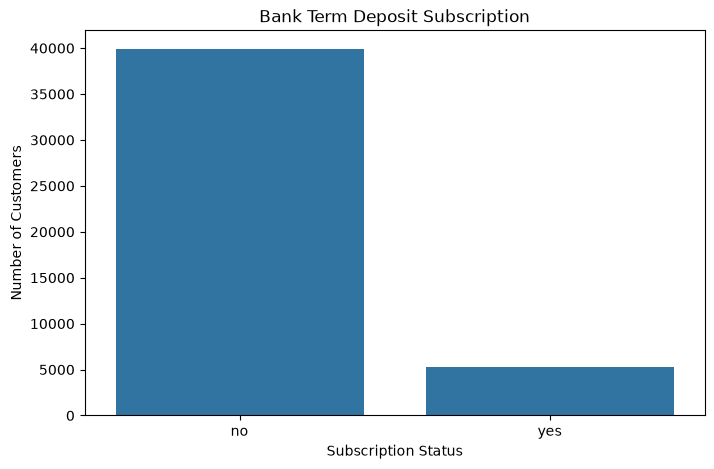

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='y')

plt.title('Bank Term Deposit Subscription')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')

plt.show()

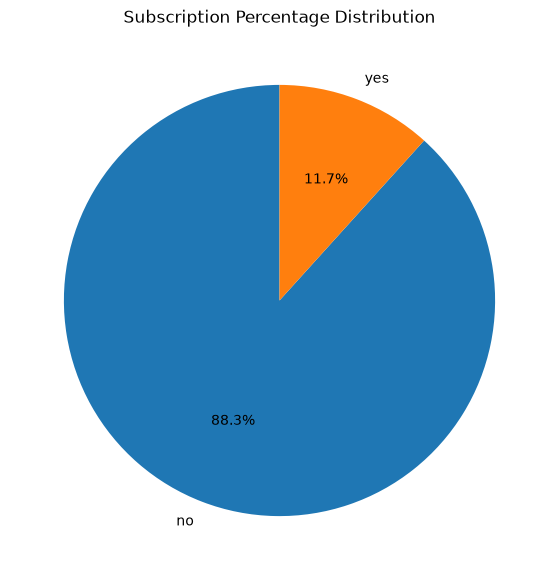

In [13]:
plt.figure(figsize=(7, 7))

df['y'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Subscription Percentage Distribution')
plt.ylabel('')

plt.show()

## 7. Customer Segmentation Analysis

### 7.1 Age Group Analysis

In [14]:
# Create age groups

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        'Below 25',
        '25-35',
        '35-45',
        '45-55',
        '55-65',
        'Above 65'
    ]
)

print(df['age_group'].value_counts().sort_index())

age_group
Below 25     1336
25-35       15571
35-45       13856
45-55        9548
55-65        4149
Above 65      751
Name: count, dtype: int64


In [15]:
age_distribution = df['age_group'].value_counts().sort_index()

print(age_distribution)

age_group
Below 25     1336
25-35       15571
35-45       13856
45-55        9548
55-65        4149
Above 65      751
Name: count, dtype: int64


In [16]:
age_subscription = pd.crosstab(
    df['age_group'],
    df['y']
)

print(age_subscription)

y             no   yes
age_group             
Below 25    1016   320
25-35      13702  1869
35-45      12555  1301
45-55       8655   893
55-65       3563   586
Above 65     431   320


In [17]:
age_subscription_rate = (
    df.groupby('age_group', observed=False)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
)

print(age_subscription_rate.round(2))

age_group
Below 25    23.95
25-35       12.00
35-45        9.39
45-55        9.35
55-65       14.12
Above 65    42.61
Name: y, dtype: float64


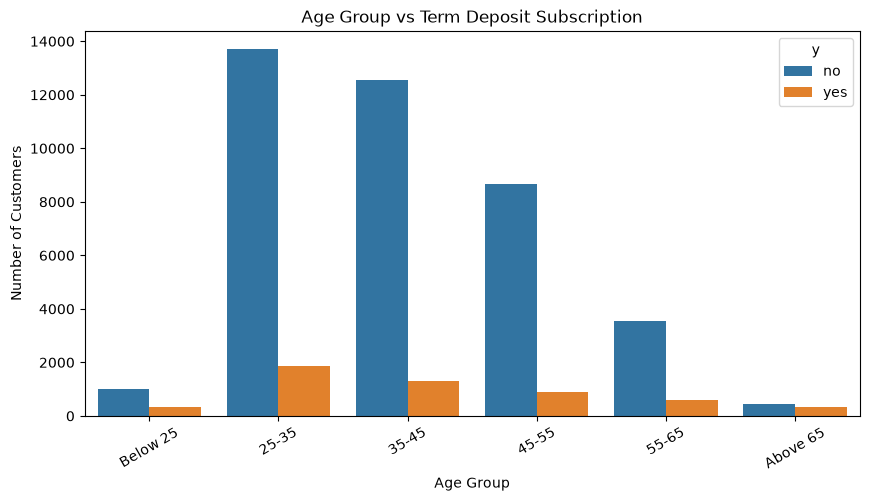

In [18]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='age_group',
    hue='y'
)

plt.title('Age Group vs Term Deposit Subscription')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')

plt.xticks(rotation=30)
plt.show()

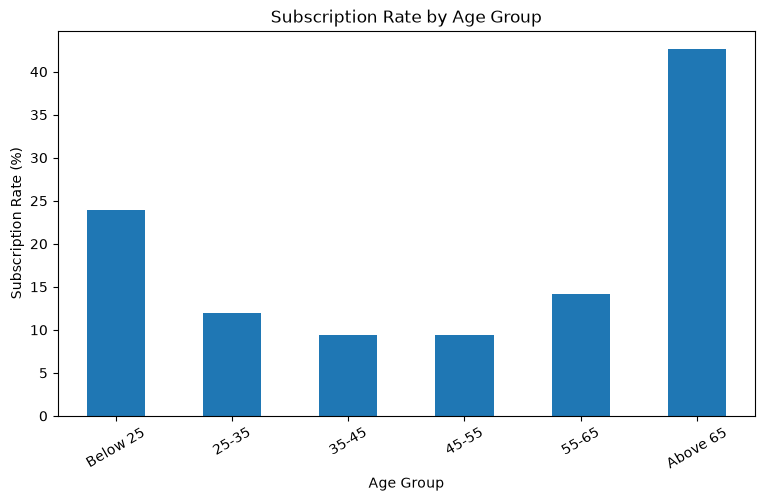

In [19]:
plt.figure(figsize=(9, 5))

age_subscription_rate.plot(kind='bar')

plt.title('Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')

plt.xticks(rotation=30)
plt.show()

### 7.2 Job Category Analysis

In [20]:
# Count customers in each job category

job_distribution = df['job'].value_counts()

print(job_distribution)

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


In [21]:
# Cross-tabulation of job and subscription

job_subscription = pd.crosstab(
    df['job'],
    df['y']
)

print(job_subscription)

y                no   yes
job                      
admin.         4540   631
blue-collar    9024   708
entrepreneur   1364   123
housemaid      1131   109
management     8157  1301
retired        1748   516
self-employed  1392   187
services       3785   369
student         669   269
technician     6757   840
unemployed     1101   202
unknown         254    34


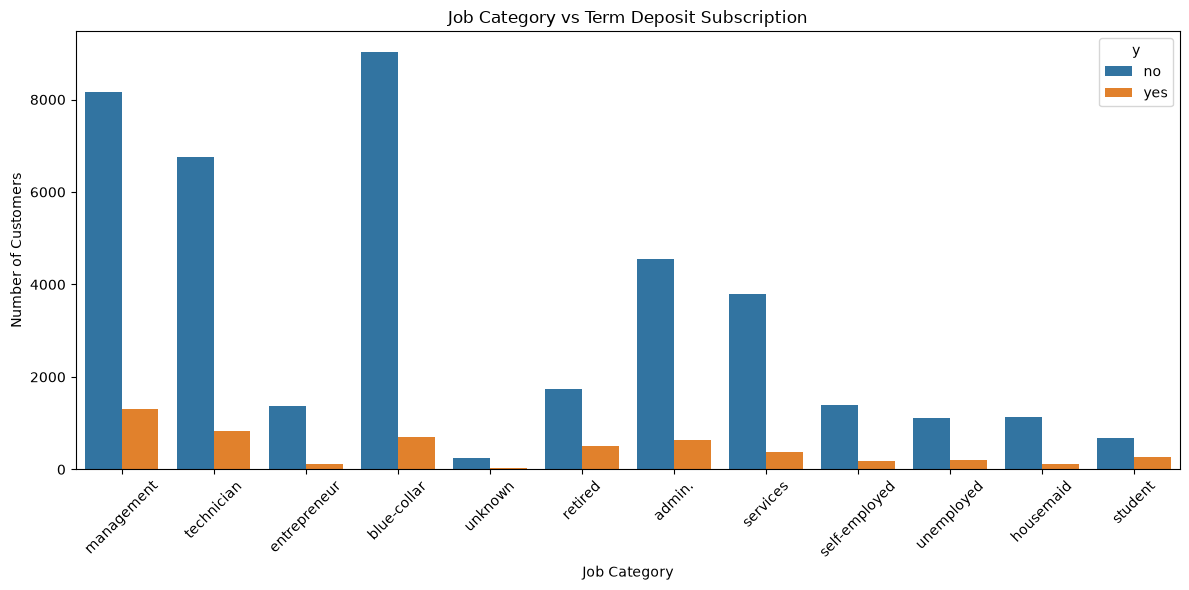

In [22]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y'
)

plt.title('Job Category vs Term Deposit Subscription')
plt.xlabel('Job Category')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
# Calculate job-wise subscription rate

job_subscription_rate = (
    df.groupby('job')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
)

print(job_subscription_rate.sort_values(ascending=False).round(2))

job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64


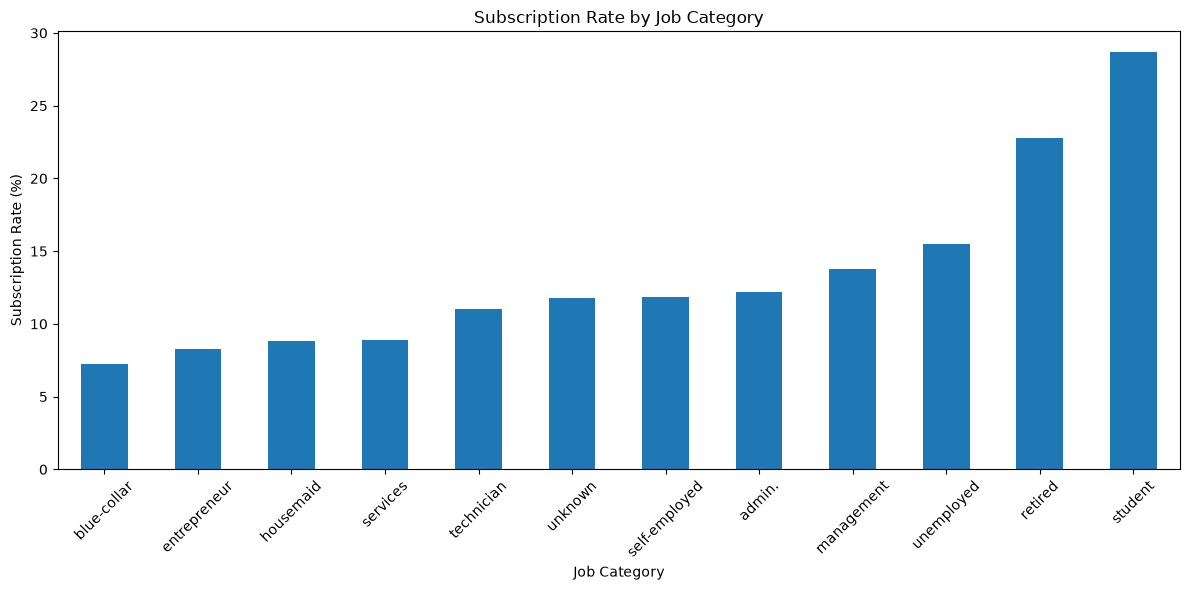

In [25]:
plt.figure(figsize=(12, 6))

job_subscription_rate.sort_values().plot(kind='bar')

plt.title('Subscription Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7.3 Education Level Analysis

In [26]:
# Count customers by education level

education_distribution = df['education'].value_counts()

print(education_distribution)

education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64


In [27]:
# Cross-tabulation

education_subscription = pd.crosstab(
    df['education'],
    df['y']
)

print(education_subscription)

y             no   yes
education             
primary     6260   591
secondary  20752  2450
tertiary   11305  1996
unknown     1605   252


In [28]:
education_subscription_rate = (
    df.groupby('education')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
)

print(
    education_subscription_rate
    .sort_values(ascending=False)
    .round(2)
)

education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: y, dtype: float64


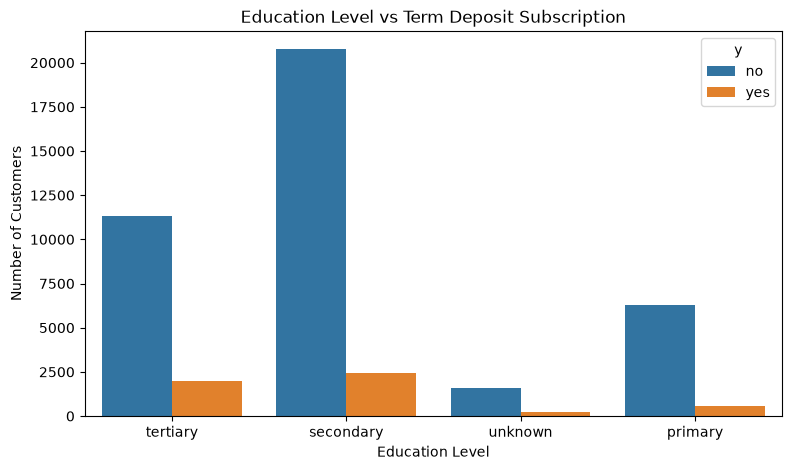

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='education',
    hue='y'
)

plt.title('Education Level vs Term Deposit Subscription')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.show()

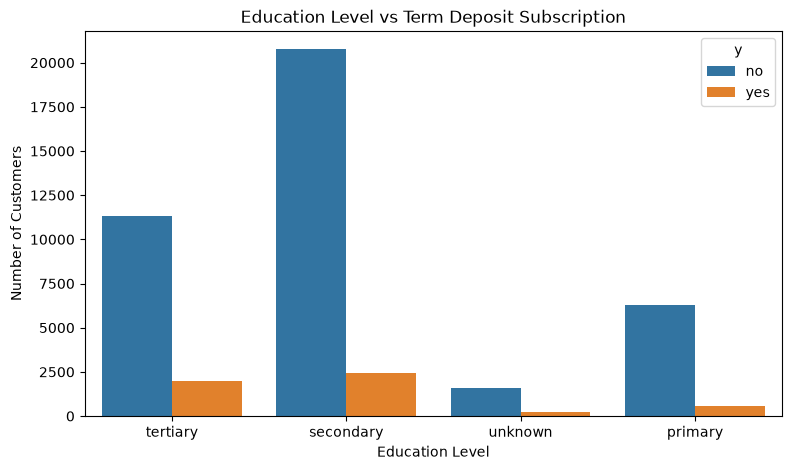

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='education',
    hue='y'
)

plt.title('Education Level vs Term Deposit Subscription')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.show()

In [31]:
print(
    education_subscription_rate
    .sort_values(ascending=False)
    .round(2)
)

education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: y, dtype: float64


### 7.4 Marital Status Analysis

In [32]:
# Count customers by marital status

marital_distribution = df['marital'].value_counts()

print(marital_distribution)

marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64


In [33]:
# Cross-tabulation

marital_subscription = pd.crosstab(
    df['marital'],
    df['y']
)

print(marital_subscription)

y            no   yes
marital              
divorced   4585   622
married   24459  2755
single    10878  1912


In [34]:
marital_subscription_rate = (
    df.groupby('marital')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
)

print(
    marital_subscription_rate
    .sort_values(ascending=False)
    .round(2)
)

marital
single      14.95
divorced    11.95
married     10.12
Name: y, dtype: float64


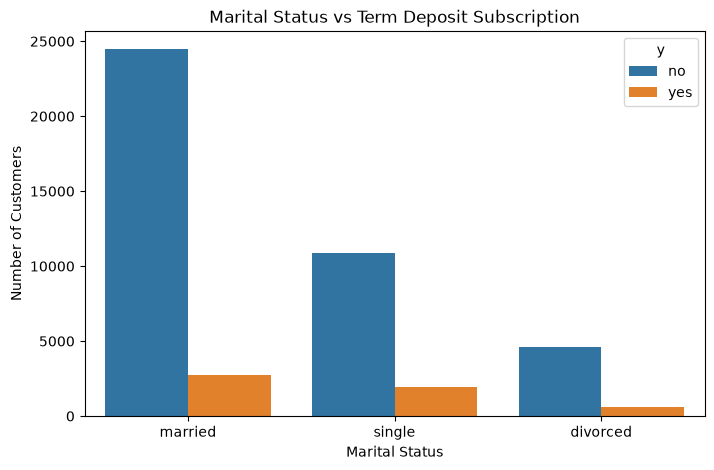

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='marital',
    hue='y'
)

plt.title('Marital Status vs Term Deposit Subscription')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.show()

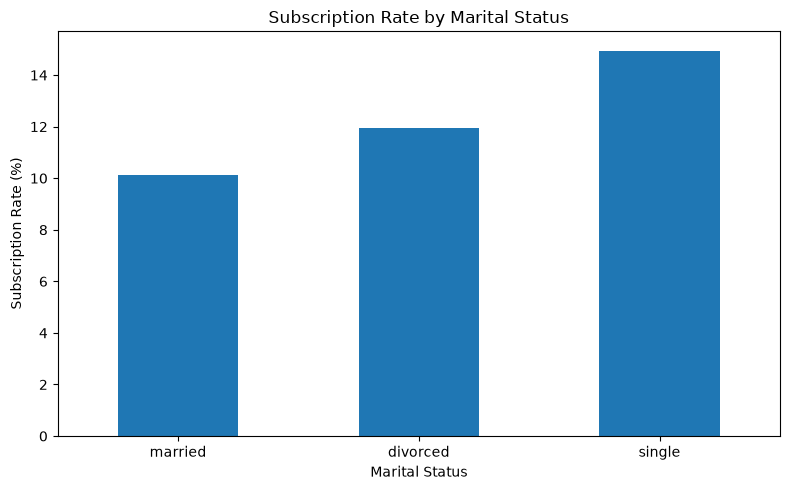

In [36]:
plt.figure(figsize=(8, 5))

marital_subscription_rate.sort_values().plot(kind='bar')

plt.title('Subscription Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Subscription Rate (%)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.5 Account Balance Analysis

Objective: To investigate the relationship between customers' account balance and term deposit subscription.

In [37]:
# Account Balance Summary

print(df['balance'].describe())

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64


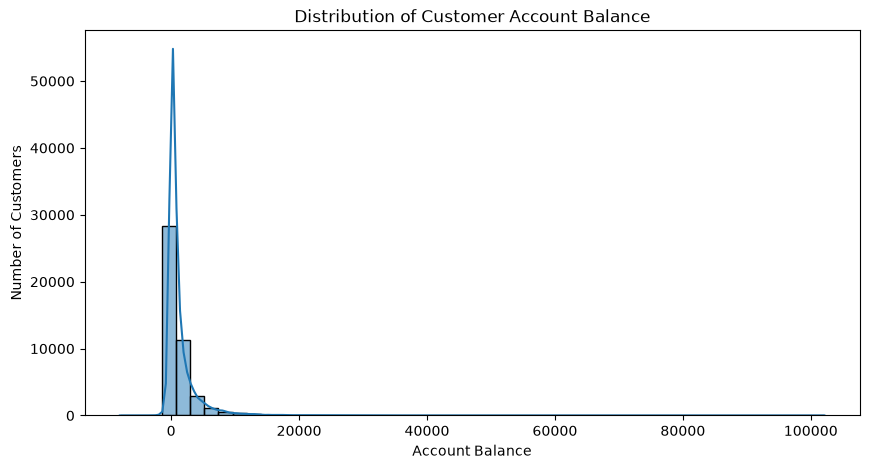

In [38]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='balance',
    bins=50,
    kde=True
)

plt.title('Distribution of Customer Account Balance')
plt.xlabel('Account Balance')
plt.ylabel('Number of Customers')

plt.show()

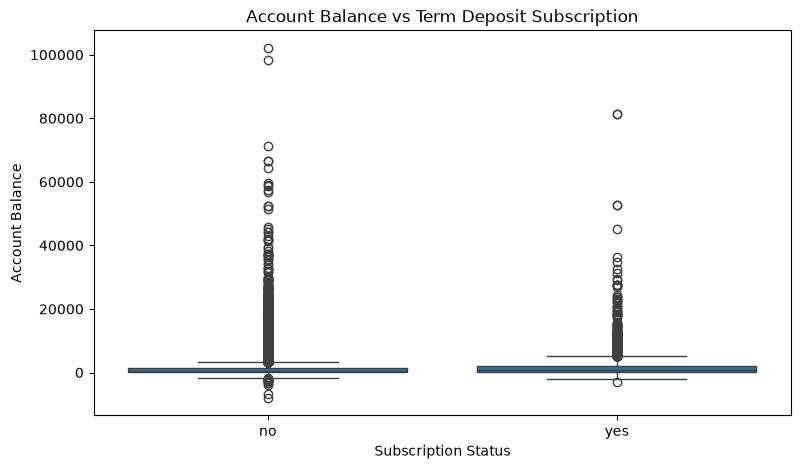

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='y',
    y='balance'
)

plt.title('Account Balance vs Term Deposit Subscription')
plt.xlabel('Subscription Status')
plt.ylabel('Account Balance')

plt.show()

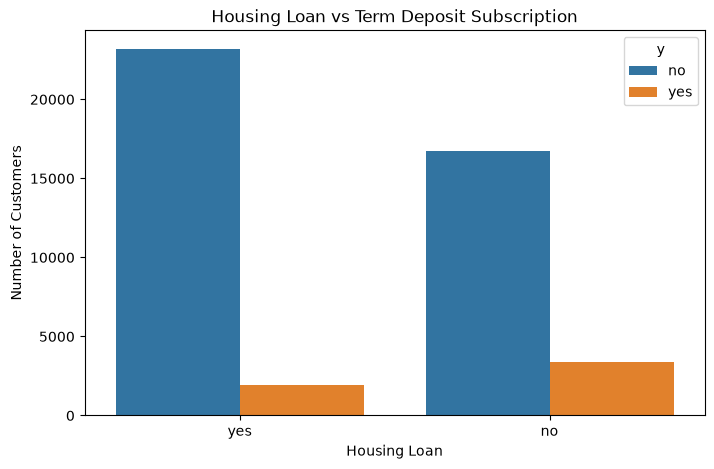

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='housing',
    hue='y'
)

plt.title('Housing Loan vs Term Deposit Subscription')
plt.xlabel('Housing Loan')
plt.ylabel('Number of Customers')

plt.show()

In [41]:
housing_rate = pd.crosstab(
    df['housing'],
    df['y'],
    normalize='index'
) * 100

print(housing_rate)

y               no        yes
housing                      
no       83.297645  16.702355
yes      92.300040   7.699960


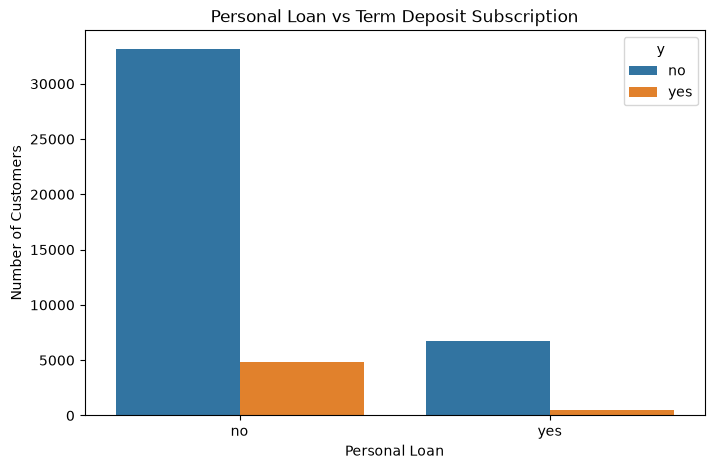

In [42]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='loan',
    hue='y'
)

plt.title('Personal Loan vs Term Deposit Subscription')
plt.xlabel('Personal Loan')
plt.ylabel('Number of Customers')

plt.show()

In [43]:
loan_rate = pd.crosstab(
    df['loan'],
    df['y'],
    normalize='index'
) * 100

print(loan_rate)

y            no        yes
loan                      
no    87.344273  12.655727
yes   93.318609   6.681391


### 7.6 Campaign Contact Analysis

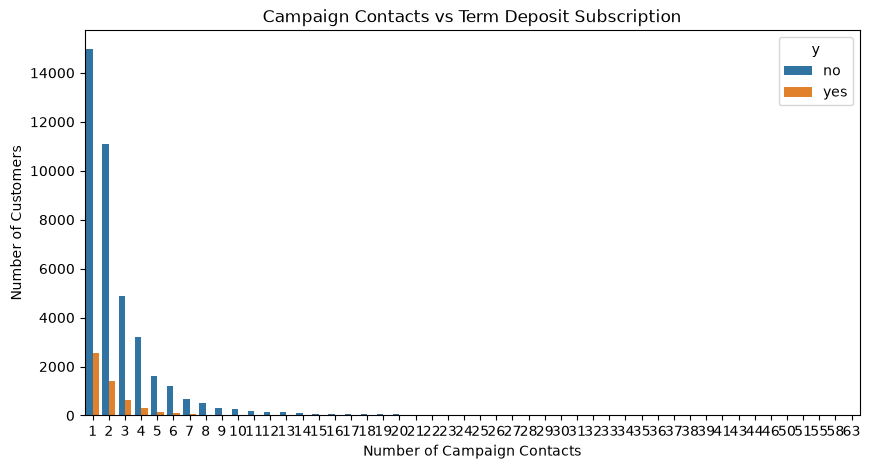

In [44]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='campaign',
    hue='y'
)

plt.title('Campaign Contacts vs Term Deposit Subscription')
plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Number of Customers')

plt.show()

In [45]:
campaign_rate = pd.crosstab(
    df['campaign'],
    df['y'],
    normalize='index'
) * 100

print(campaign_rate)

y                 no        yes
campaign                       
1          85.402417  14.597583
2          88.796481  11.203519
3          88.806376  11.193624
4          90.999432   9.000568
5          92.120181   7.879819
6          92.873741   7.126259
7          93.605442   6.394558
8          94.074074   5.925926
9          93.577982   6.422018
10         94.736842   5.263158
11         92.039801   7.960199
12         97.419355   2.580645
13         95.488722   4.511278
14         95.698925   4.301075
15         95.238095   4.761905
16         97.468354   2.531646
17         91.304348   8.695652
18        100.000000   0.000000
19        100.000000   0.000000
20         97.674419   2.325581
21         97.142857   2.857143
22        100.000000   0.000000
23        100.000000   0.000000
24         95.000000   5.000000
25        100.000000   0.000000
26        100.000000   0.000000
27        100.000000   0.000000
28        100.000000   0.000000
29         93.750000   6.250000
30      

### 7.7 Communication Method Analysis

Objective: To investigate the relationship between communication methods and term deposit subscriptions.

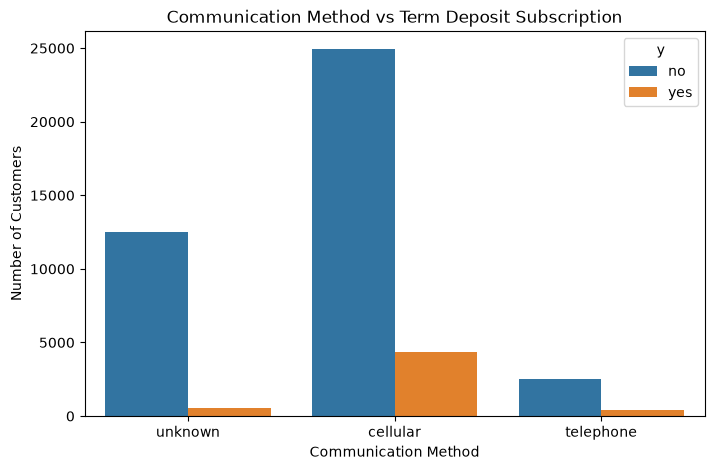

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='contact',
    hue='y'
)

plt.title('Communication Method vs Term Deposit Subscription')
plt.xlabel('Communication Method')
plt.ylabel('Number of Customers')

plt.show()

In [47]:
contact_rate = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

print(contact_rate)

y                 no        yes
contact                        
cellular   85.081100  14.918900
telephone  86.579491  13.420509
unknown    95.929339   4.070661


### 7.8 Previous Campaign Outcome Analysis

Objective: To investigate whether previous campaign outcomes influence current term deposit subscriptions.

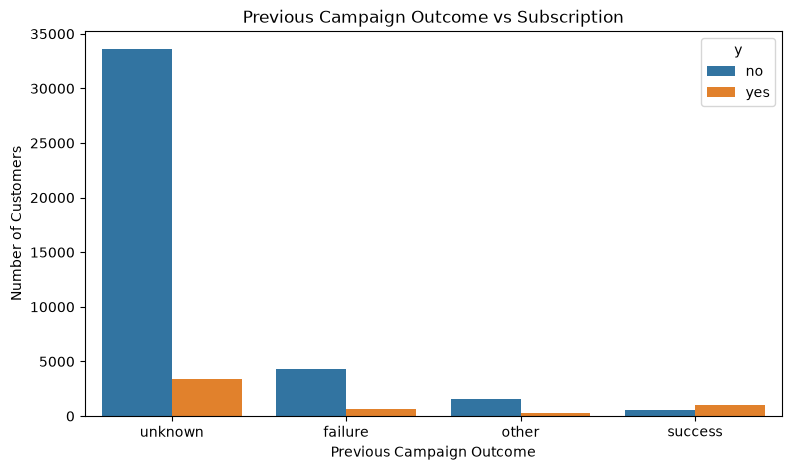

In [48]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='poutcome',
    hue='y'
)

plt.title('Previous Campaign Outcome vs Subscription')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Number of Customers')

plt.show()

In [49]:
previous_rate = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

print(previous_rate)

y                no        yes
poutcome                      
failure   87.390329  12.609671
other     83.315217  16.684783
success   35.274653  64.725347
unknown   90.838497   9.161503


### 7.9 Day and Duration Analysis

Objective: To investigate the relationship between campaign duration, contact day and term deposit subscription.

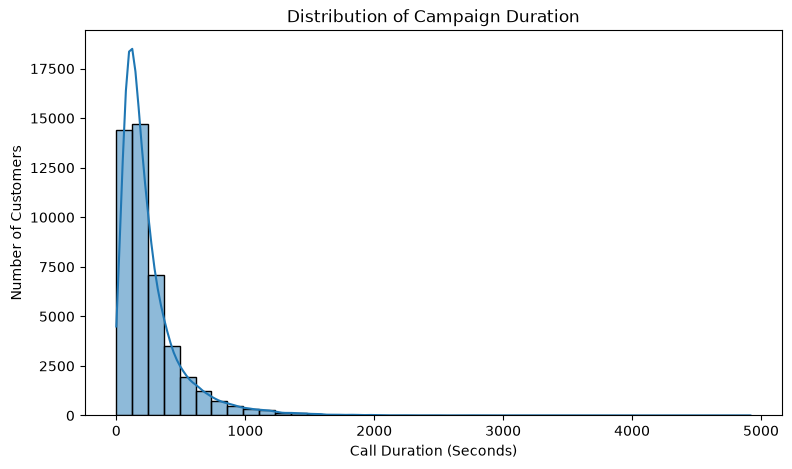

In [50]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='duration', bins=40, kde=True)

plt.title('Distribution of Campaign Duration')
plt.xlabel('Call Duration (Seconds)')
plt.ylabel('Number of Customers')

plt.show()

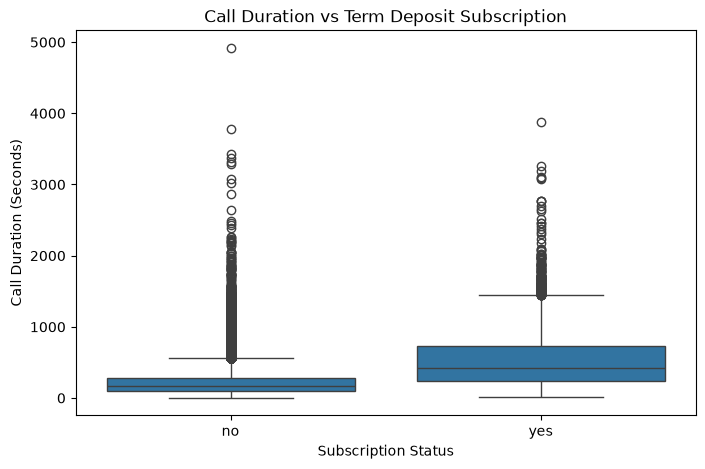

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='y', y='duration')

plt.title('Call Duration vs Term Deposit Subscription')
plt.xlabel('Subscription Status')
plt.ylabel('Call Duration (Seconds)')

plt.show()

In [52]:
print(df.groupby('y')['duration'].mean())

y
no     221.182806
yes    537.294574
Name: duration, dtype: float64


### 7.10 Correlation Analysis

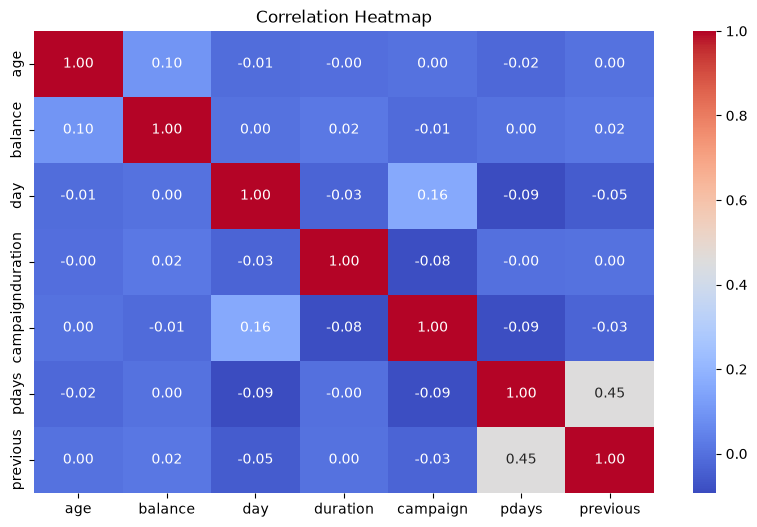

In [53]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Key Observations

1. Age and balance have a weak positive correlation (0.10).
2. Campaign and day show a weak positive correlation (0.16).
3. Pdays and previous have a moderate positive correlation (0.45).
4. Most numerical variables have very weak correlations.
5. No strong linear relationship is observed among most numerical features.

### Conclusion

The correlation heatmap helps identify relationships between numerical variables and understand their association within the dataset.

# Final Conclusion – Bank Marketing EDA

- Analyzed customer demographic and financial information.
- Studied term deposit subscription patterns.
- Identified the impact of campaign duration.
- Compared subscription rates across different customer groups.
- Analyzed previous campaign outcomes.
- Used visualizations to identify important business patterns.

### Business Recommendations

1. Focus on customers with successful previous campaign history.
2. Improve customer communication strategies.
3. Prioritize meaningful and longer customer interactions.
4. Segment customers based on their characteristics.
5. Optimize future marketing campaigns using data insights.